In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

df = pd.read_csv('data/supermarket.csv')

# Menambahkan kolom total penjualan (Unit price * Quantity)
df['Total Sales'] = df['Unit price'] * df['Quantity']

df

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Date,Time,Payment,Rating,Total Sales
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,1/5/2019,13:08,Ewallet,9.1,522.83
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3/8/2019,10:29,Cash,9.6,76.40
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,3/3/2019,13:23,Credit card,7.4,324.31
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,1/27/2019,20:33,Ewallet,8.4,465.76
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,2/8/2019,10:37,Ewallet,5.3,604.17
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,233-67-5758,C,Naypyitaw,Normal,Male,Health and beauty,40.35,1,1/29/2019,13:46,Ewallet,6.2,40.35
996,303-96-2227,B,Mandalay,Normal,Female,Home and lifestyle,97.38,10,3/2/2019,17:16,Ewallet,4.4,973.80
997,727-02-1313,A,Yangon,Member,Male,Food and beverages,31.84,1,2/9/2019,13:22,Cash,7.7,31.84
998,347-56-2442,A,Yangon,Normal,Male,Home and lifestyle,65.82,1,2/22/2019,15:33,Cash,4.1,65.82


Exploratory Data Analysis (EDA)

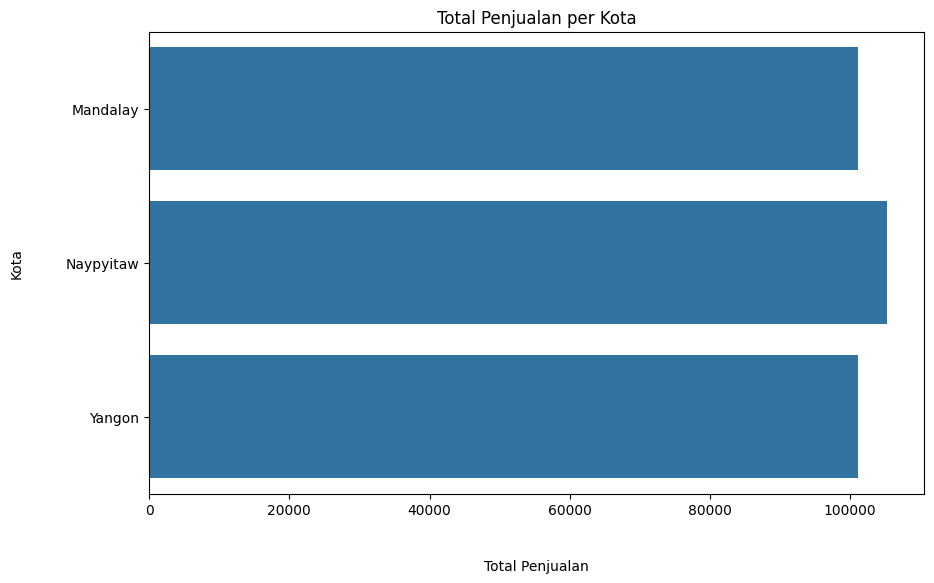

In [2]:
# Visualisasi Total Penjualan per Kota
city_sales = df.groupby('City')['Total Sales'].sum()

plt.figure(figsize=(10, 6))
sns.barplot(x = city_sales.values, y = city_sales.index)
plt.title('Total Penjualan per Kota')
plt.xlabel('Total Penjualan', labelpad=30)
plt.ylabel('Kota', labelpad=30)
plt.show()


FORECASTING REGRESI LINEAR

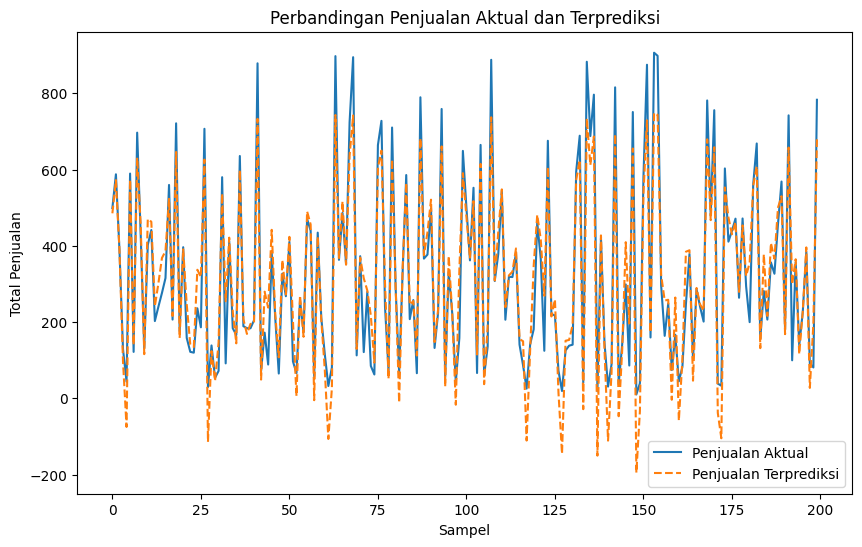

In [3]:
# Memilih fitur yang relevan untuk model
X = df[['Unit price', 'Quantity']]
y = df['Total Sales']

# Membagi data menjadi set pelatihan dan pengujian
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Menginisialisasi model regresi linear
model = LinearRegression()

# Melatih model dengan data pelatihan
model.fit(X_train, y_train)

# Membuat prediksi pada set pengujian
y_pred = model.predict(X_test)

# Visualisasi Hasil Prediksi vs Nilai Aktual
plt.figure(figsize=(10, 6))
plt.plot(y_test.values, label='Penjualan Aktual')
plt.plot(y_pred, label='Penjualan Terprediksi', linestyle='--')
plt.title('Perbandingan Penjualan Aktual dan Terprediksi')
plt.xlabel('Sampel')
plt.ylabel('Total Penjualan')
plt.legend()
plt.show()


In [4]:
# Menghitung Mean Squared Error (MSE)

mse = mean_squared_error(y_test, y_pred)
print(f'Mean Squared Error: {mse}')

Mean Squared Error: 5649.0208713729635
